# PySL Tutorial: Sturm-Liouville Calcuations in Python

This notebook demonstrates the capabilities and usage of PySL, a Python library for performing Sturm-Liouville eigenvalue problems from numerical boundary data using the Rayleigh quotient.

The Sturm-Liouville equation has the form:

$$-\frac{d}{dx}\left[p(x)\frac{dy}{dx}\right] + q(x)y = \lambda w(x)y$$

where $\lambda$ represents the eigenvalue we want to estimate.

In [1]:
#Imports
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
from sturmliouville import SturmLiouville

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

/home/pgclark/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Vibrating string problem

The Sturm-Liouville ODE for a vibrating string can be obtained by $p(x) = 1$, $q(x) = 0$, and $w(x) = 1$.

The analytical eigenvalues for this problem with Dirichlet boundary conditions on $[0, 1]$ are $\lambda_n = n^2\pi^2$.

In [2]:
x_points = np.linspace(0, 1, 11)

p_data = {x: 1.0 for x in x_points}
q_data = {x: 0.0 for x in x_points}
w_data = {x: 1.0 for x in x_points}

sl = SturmLiouville()
sl.p(p_data).q(q_data).w(w_data)
sl.set_boundary_conditions('dirichlet')
sl.set_basis('fourier')
sl.preprocess(n_points=100)

print(f"Domain: {sl.get_domain()}")
print(f"Grid points: {len(sl.get_grid())}")

Domain: (np.float64(0.0), np.float64(1.0))
Grid points: 100


## Visualizing basis functions

Now we can compare the Fourier basis to other solution basis vectors such as polynomial functions.

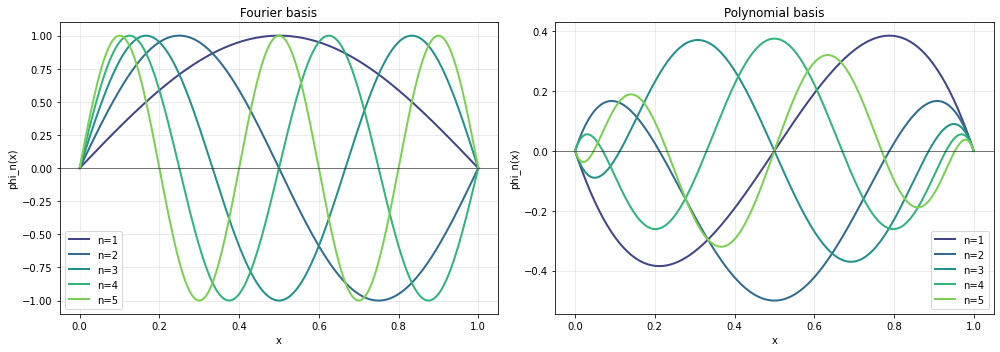

In [3]:
sl_fourier = SturmLiouville()
sl_fourier.p(p_data).q(q_data).w(w_data)
sl_fourier.set_boundary_conditions('dirichlet')
sl_fourier.set_basis('fourier')
sl_fourier.preprocess(n_points=200)

fourier_basis = sl_fourier.generate_basis(n_basis=5)
grid = sl_fourier.get_grid()

sl_poly = SturmLiouville()
sl_poly.p(p_data).q(q_data).w(w_data)
sl_poly.set_boundary_conditions('dirichlet')
sl_poly.set_basis('polynomial', polynomial_type='legendre')
sl_poly.preprocess(n_points=200)

poly_basis = sl_poly.generate_basis(n_basis=5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = plt.cm.viridis(np.linspace(0.2, 0.8, 5))

for i, basis_func in enumerate(fourier_basis):
    axes[0].plot(grid, basis_func, color=colors[i], linewidth=2, label=f'n={i+1}')
axes[0].set_xlabel('x')
axes[0].set_ylabel('phi_n(x)')
axes[0].set_title('Fourier basis')
axes[0].legend()
axes[0].axhline(y=0, color='black', linewidth=0.5)

for i, basis_func in enumerate(poly_basis):
    axes[1].plot(grid, basis_func, color=colors[i], linewidth=2, label=f'n={i+1}')
axes[1].set_xlabel('x')
axes[1].set_ylabel('phi_n(x)')
axes[1].set_title('Polynomial basis')
axes[1].legend()
axes[1].axhline(y=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

## Estimating eigenvalues with the Rayleigh quotient

The Rayleigh quotient provides upper bounds for eigenvalues:

$$\lambda[y] = \frac{\int_a^b \left[p(x)(y')^2 + q(x)y^2\right]dx}{\int_a^b w(x)y^2 dx}$$

For our simple vibrating string - $p=1$, $q=0$, $w=1$ - the exact first eigenvalue is $\lambda_1 = \pi^2 \approx 9.8696$.

In [4]:
lambda_1_fourier = sl_fourier.rayleigh_quotient_from_coefficients([1.0])
lambda_1_poly = sl_poly.rayleigh_quotient_from_coefficients([1.0])
lambda_exact = np.pi**2

print("First eigenvalue estimates:")
print(f"Fourier: {lambda_1_fourier:.6f}, error: {abs(lambda_1_fourier - lambda_exact):.2e}")
print(f"Polynomial: {lambda_1_poly:.6f}, error: {abs(lambda_1_poly - lambda_exact):.2e}")

First eigenvalue estimates:
Fourier: 9.868785, error: 8.20e-04
Polynomial: 41.979028, error: 3.21e+01


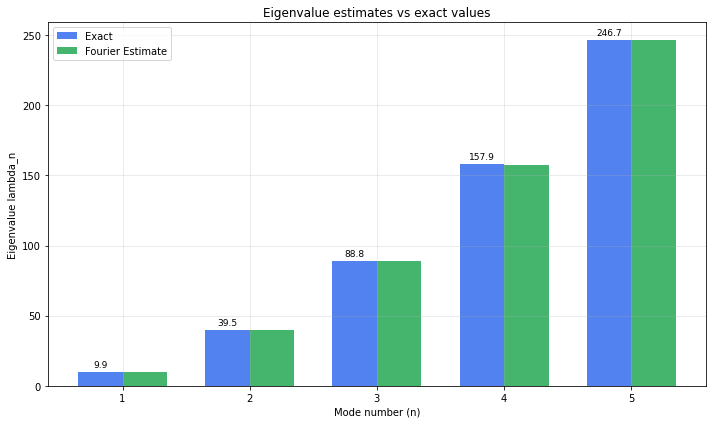

In [5]:
n_eigenvalues = 5
exact_eigenvalues = [(n**2) * np.pi**2 for n in range(1, n_eigenvalues + 1)]
fourier_eigenvalues = [sl_fourier.rayleigh_quotient_from_coefficients(
    [1.0 if j == i else 0.0 for j in range(n_eigenvalues)]
) for i in range(n_eigenvalues)]
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(n_eigenvalues)
width = 0.35

bars1 = ax.bar(x - width/2, exact_eigenvalues, width, label='Exact', color='#2563eb', alpha=0.8)
bars2 = ax.bar(x + width/2, fourier_eigenvalues, width, label='Fourier Estimate', color='#16a34a', alpha=0.8)

ax.set_xlabel('Mode number (n)')
ax.set_ylabel('Eigenvalue lambda_n')
ax.set_title('Eigenvalue estimates vs exact values')
ax.set_xticks(x)
ax.set_xticklabels([f'{i+1}' for i in range(n_eigenvalues)])
ax.legend()

for bar in bars1:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Comparing Interpolation Methods

PySL supports four interpolation methods for converting sparse data to the computational grid: forward difference, backwards difference, midpoint, and cubic (spline interpolation)

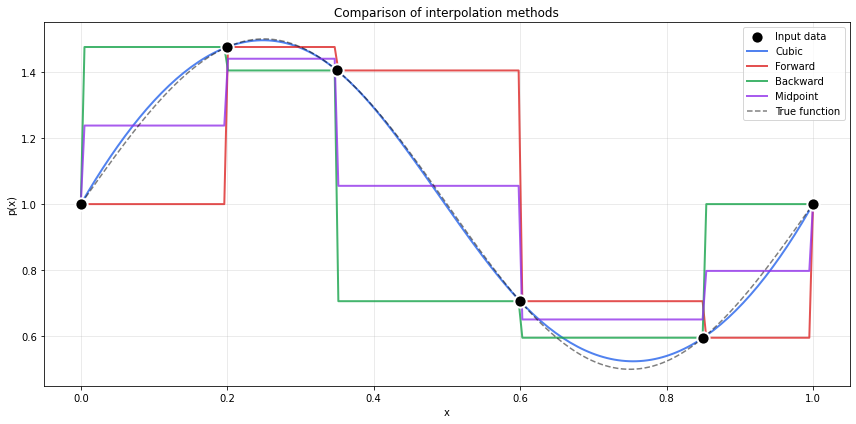

In [6]:
sparse_x = [0.0, 0.2, 0.35, 0.6, 0.85, 1.0]
sparse_p = {x: 1.0 + 0.5*np.sin(2*np.pi*x) for x in sparse_x}

methods = ['cubic', 'forward', 'backward', 'midpoint']
colors = ['#2563eb', '#dc2626', '#16a34a', '#9333ea']

fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(list(sparse_p.keys()), list(sparse_p.values()), 
           s=150, c='black', zorder=10, label='Input data', marker='o', edgecolors='white', linewidths=2)

for method, color in zip(methods, colors):
    sl_temp = SturmLiouville()
    sl_temp.p(sparse_p).q(q_data).w(w_data)
    sl_temp.set_interpolation_method(method)
    sl_temp.preprocess(n_points=200)
    
    grid = sl_temp.get_grid()
    p_interp = sl_temp.get_coefficients()['p']
    
    ax.plot(grid, p_interp, color=color, linewidth=2, label=f'{method.capitalize()}', alpha=0.8)

x_true = np.linspace(0, 1, 500)
p_true = 1.0 + 0.5*np.sin(2*np.pi*x_true)
ax.plot(x_true, p_true, 'k--', linewidth=1.5, label='True function', alpha=0.5)

ax.set_xlabel('x')
ax.set_ylabel('p(x)')
ax.set_title('Comparison of interpolation methods')
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

## Variable coefficients

Now here we use a problem where the input data is non-constant, such as arising from physical measurements.

In [7]:
#Noise simulating measurement error
np.random.seed(42)
x_measured = np.linspace(0, 1, 15)

#Ex: non-uniform string
p_measured = {x: 1.0 + 0.3*x + 0.02*np.random.randn() for x in x_measured}
q_measured = {x: -0.5*x*(1-x) + 0.01*np.random.randn() for x in x_measured}
w_measured = {x: 1.0 + 0.2*np.sin(np.pi*x) + 0.02*np.random.randn() for x in x_measured}

# Physicality constraints
p_measured = {x: max(0.1, v) for x, v in p_measured.items()}
w_measured = {x: max(0.1, v) for x, v in w_measured.items()}

sl_complex = SturmLiouville()
sl_complex.p(p_measured).q(q_measured).w(w_measured)
sl_complex.set_boundary_conditions('dirichlet')
sl_complex.set_basis('fourier')
sl_complex.set_interpolation_method('cubic')
sl_complex.preprocess(n_points=200)

basis = sl_complex.generate_basis(n_basis=8)
grid = sl_complex.get_grid()
coeffs = sl_complex.get_coefficients()

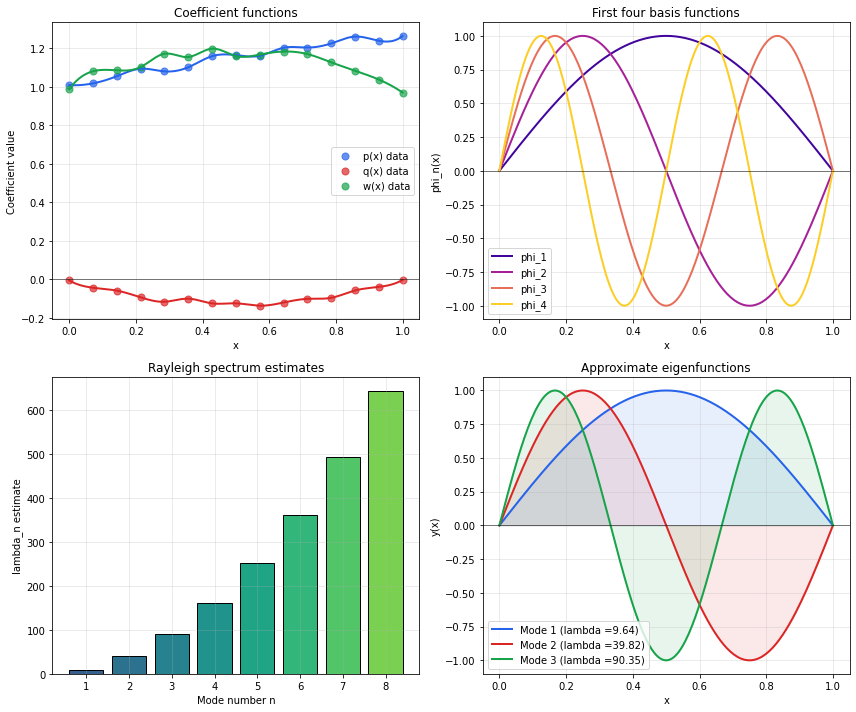

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

ax = axes[0, 0]
ax.scatter(list(p_measured.keys()), list(p_measured.values()), s=50, c='#2563eb', alpha=0.7, label='p(x) data')
ax.scatter(list(q_measured.keys()), list(q_measured.values()), s=50, c='#dc2626', alpha=0.7, label='q(x) data')
ax.scatter(list(w_measured.keys()), list(w_measured.values()), s=50, c='#16a34a', alpha=0.7, label='w(x) data')
ax.plot(grid, coeffs['p'], '#2563eb', linewidth=2)
ax.plot(grid, coeffs['q'], '#dc2626', linewidth=2)
ax.plot(grid, coeffs['w'], '#16a34a', linewidth=2)
ax.set_xlabel('x')
ax.set_ylabel('Coefficient value')
ax.set_title('Coefficient functions')
ax.legend()
ax.axhline(y=0, color='black', linewidth=0.5)

ax = axes[0, 1]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, 4))
for i in range(4):
    ax.plot(grid, basis[i], color=colors[i], linewidth=2, label=f'phi_{i+1}')
ax.set_xlabel('x')
ax.set_ylabel('phi_n(x)')
ax.set_title('First four basis functions')
ax.legend()
ax.axhline(y=0, color='black', linewidth=0.5)

eigenvalue_estimates = []
for i in range(8):
    coeffs_trial = [1.0 if j == i else 0.0 for j in range(8)]
    lam = sl_complex.rayleigh_quotient_from_coefficients(coeffs_trial)
    eigenvalue_estimates.append(lam)

ax = axes[1, 0]
ax.bar(range(1, 9), eigenvalue_estimates, color=plt.cm.viridis(np.linspace(0.3, 0.8, 8)), edgecolor='black')
ax.set_xlabel('Mode number n')
ax.set_ylabel('lambda_n estimate')
ax.set_title('Rayleigh spectrum estimates')

ax = axes[1, 1]
for i, color in zip(range(3), ['#2563eb', '#dc2626', '#16a34a']):
    eigenfunction = basis[i]
    eigenfunction = eigenfunction / np.max(np.abs(eigenfunction))
    ax.plot(grid, eigenfunction, color=color, linewidth=2, label=f'Mode {i+1} (lambda ={eigenvalue_estimates[i]:.2f})')
    ax.fill_between(grid, 0, eigenfunction, color=color, alpha=0.1)

ax.set_xlabel('x')
ax.set_ylabel('y(x)')
ax.set_title('Approximate eigenfunctions')
ax.legend()
ax.axhline(y=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

## Boundary Conditions

Comparing how choice of boundary condition (Dirichlet, Neumann, mixed) affect the basis functions.

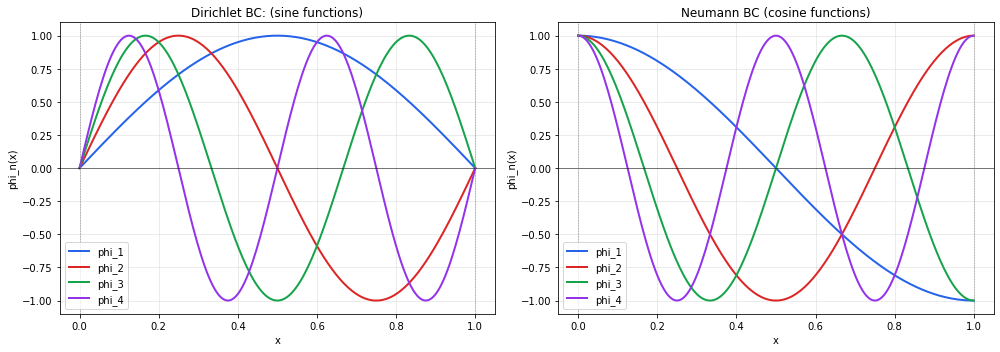

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Dirichlet boundary conditions: y(0)=y(1)=0
sl_dirichlet = SturmLiouville()
sl_dirichlet.p(p_data).q(q_data).w(w_data)
sl_dirichlet.set_boundary_conditions('dirichlet')
sl_dirichlet.set_basis('fourier')
sl_dirichlet.preprocess(n_points=200)
basis_dirichlet = sl_dirichlet.generate_basis(n_basis=4)
grid = sl_dirichlet.get_grid()

# Neumann boundary conditions: y'(0)=y'(1)=1
sl_neumann = SturmLiouville()
sl_neumann.p(p_data).q(q_data).w(w_data)
sl_neumann.set_boundary_conditions('neumann')
sl_neumann.set_basis('fourier')
sl_neumann.preprocess(n_points=200)
basis_neumann = sl_neumann.generate_basis(n_basis=4)

colors = ['#2563eb', '#dc2626', '#16a34a', '#9333ea']

ax = axes[0]
for i, (basis_func, color) in enumerate(zip(basis_dirichlet, colors)):
    ax.plot(grid, basis_func, color=color, linewidth=2, label=f'phi_{i+1}')
ax.axhline(y=0, color='black', linewidth=0.5)
ax.axvline(x=0, color='gray', linewidth=0.5, linestyle='--')
ax.axvline(x=1, color='gray', linewidth=0.5, linestyle='--')
ax.set_xlabel('x')
ax.set_ylabel('phi_n(x)')
ax.set_title('Dirichlet BC: (sine functions)')
ax.legend()

ax = axes[1]
for i, (basis_func, color) in enumerate(zip(basis_neumann, colors)):
    ax.plot(grid, basis_func, color=color, linewidth=2, label=f'phi_{i+1}')
ax.axhline(y=0, color='black', linewidth=0.5)
ax.axvline(x=0, color='gray', linewidth=0.5, linestyle='--')
ax.axvline(x=1, color='gray', linewidth=0.5, linestyle='--')
ax.set_xlabel('x')
ax.set_ylabel('phi_n(x)')
ax.set_title("Neumann BC (cosine functions)")
ax.legend()

plt.tight_layout()
plt.show()

## Custom basis functions

PySL also allows user-defined basis functions.

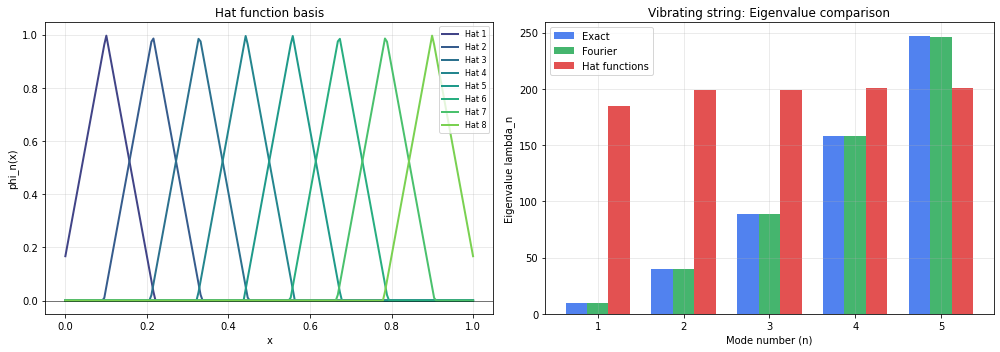

In [10]:
#The "hat" function is a piecewise linear function
def make_hat_function(center, width):
    def hat(x):
        result = np.zeros_like(x)
        left = (x >= center - width) & (x <= center)
        right = (x > center) & (x <= center + width)
        result[left] = (x[left] - (center - width)) / width
        result[right] = ((center + width) - x[right]) / width
        return result
    return hat

# Create "hat" functions centered at different positions
n_hats = 8
centers = np.linspace(0.1, 0.9, n_hats)
width = 0.12
custom_functions = [make_hat_function(c, width) for c in centers]

sl_custom = SturmLiouville()
sl_custom.p(p_data).q(q_data).w(w_data)
sl_custom.set_custom_basis(custom_functions)
sl_custom.preprocess(n_points=200)
basis_custom = sl_custom.generate_basis(n_basis=n_hats)
grid = sl_custom.get_grid()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
colors_hat = plt.cm.viridis(np.linspace(0.2, 0.8, n_hats))
for i, (basis_func, color) in enumerate(zip(basis_custom, colors_hat)):
    ax.plot(grid, basis_func, color=color, linewidth=2, label=f'Hat {i+1}')
ax.set_xlabel('x')
ax.set_ylabel('phi_n(x)')
ax.set_title('Hat function basis')
ax.legend(loc='upper right', fontsize=8)
ax.axhline(y=0, color='black', linewidth=0.5)

n_compare = min(5, n_hats)
hat_eigenvalues = [sl_custom.rayleigh_quotient_from_coefficients(
    [1.0 if j == i else 0.0 for j in range(n_hats)]
) for i in range(n_compare)]

exact_eigenvalues = [(n**2) * np.pi**2 for n in range(1, n_compare + 1)]
fourier_eigenvalues = [sl_fourier.rayleigh_quotient_from_coefficients(
    [1.0 if j == i else 0.0 for j in range(5)]
) for i in range(n_compare)]

ax = axes[1]
x_pos = np.arange(n_compare)
width_bar = 0.25

ax.bar(x_pos - width_bar, exact_eigenvalues, width_bar, label='Exact', color='#2563eb', alpha=0.8)
ax.bar(x_pos, fourier_eigenvalues, width_bar, label='Fourier', color='#16a34a', alpha=0.8)
ax.bar(x_pos + width_bar, hat_eigenvalues, width_bar, label='Hat functions', color='#dc2626', alpha=0.8)

ax.set_xlabel('Mode number (n)')
ax.set_ylabel('Eigenvalue lambda_n')
ax.set_title('Vibrating string: Eigenvalue comparison')
ax.set_xticks(x_pos)
ax.set_xticklabels([str(i+1) for i in range(n_compare)])
ax.legend()

plt.tight_layout()
plt.show()

## Convergence Study

Now we look at how convergence rates change based on the width of our finite grid mesh.

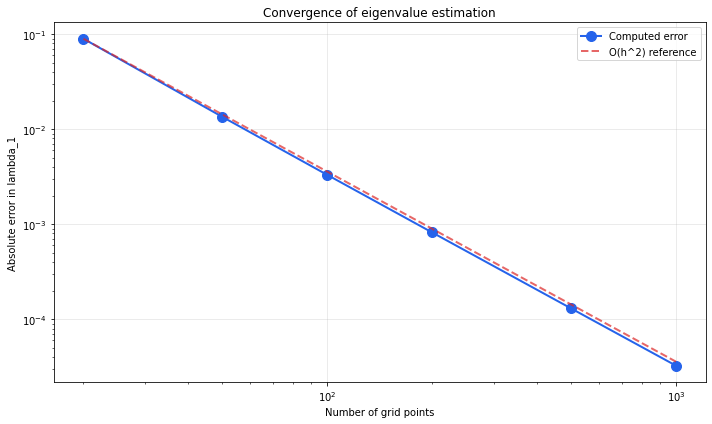

In [11]:
n_points_list = [20, 50, 100, 200, 500, 1000]
lambda_exact = np.pi**2

errors = []
for n_pts in n_points_list:
    sl_conv = SturmLiouville()
    sl_conv.p(p_data).q(q_data).w(w_data)
    sl_conv.set_boundary_conditions('dirichlet')
    sl_conv.set_basis('fourier')
    sl_conv.preprocess(n_points=n_pts)
    sl_conv.generate_basis(n_basis=1)
    
    lambda_est = sl_conv.rayleigh_quotient_from_coefficients([1.0])
    errors.append(abs(lambda_est - lambda_exact))

fig, ax = plt.subplots(figsize=(10, 6))

ax.loglog(n_points_list, errors, 'o-', color='#2563eb', linewidth=2, markersize=10, label='Computed error')

h_ref = 1.0 / np.array(n_points_list)
error_ref = errors[0] * (h_ref / h_ref[0])**2
ax.loglog(n_points_list, error_ref, '--', color='#dc2626', linewidth=2, alpha=0.7, label='O(h^2) reference')

ax.set_xlabel('Number of grid points')
ax.set_ylabel('Absolute error in lambda_1')
ax.set_title('Convergence of eigenvalue estimation')
ax.legend()

plt.tight_layout()
plt.show()

## Application: Green's Functions

One application of Sturm-Liouville eigenfunctions is constructing Green's functions for solving inhomogenous boundary value problems.

For a Sturm-Liouville operator $L$, the Green's function can be expressed as an eigenfunction expansion:

$$G(x, \xi) = \sum_{n=1}^{\infty} \frac{\phi_n(x) \phi_n(\xi)}{\lambda_n}$$

This allows us to solve the inhomogeneous problem $Ly = f(x)$ via:

$$y(x) = \int_a^b G(x, \xi) f(\xi) w(\xi) \, d\xi$$

/tmp/ipykernel_29780/895856969.py:17: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  norm_sq = np.trapz(w_grid * basis[i]**2, dx=dx)


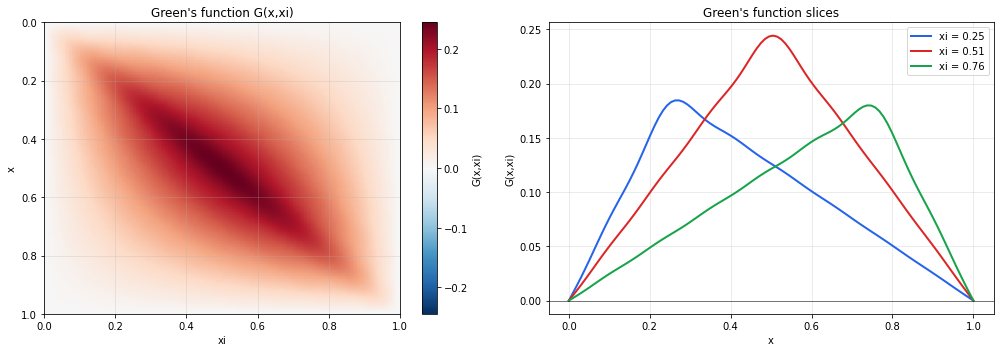

In [12]:
def construct_greens_function(sl_instance, n_terms=20):
    grid = sl_instance.get_grid()
    n_pts = len(grid)
    
    basis = sl_instance.generate_basis(n_basis=n_terms)
    
    eigenvalues = []
    normalized_basis = []
    
    for i in range(n_terms):
        coeffs = [1.0 if j == i else 0.0 for j in range(n_terms)]
        lam = sl_instance.rayleigh_quotient_from_coefficients(coeffs)
        eigenvalues.append(lam)
        
        w_grid = sl_instance.get_coefficients()['w']
        dx = grid[1] - grid[0]
        norm_sq = np.trapz(w_grid * basis[i]**2, dx=dx)
        normalized_basis.append(basis[i] / np.sqrt(norm_sq))
    
    G = np.zeros((n_pts, n_pts))
    for n in range(n_terms):
        phi_n = normalized_basis[n]
        lam_n = eigenvalues[n]
        G += np.outer(phi_n, phi_n) / lam_n
    
    return G, grid, eigenvalues, normalized_basis

# Simple problem: -y'' = f(x) w Dirchlet BCs
sl_green = SturmLiouville()
sl_green.p(p_data).q(q_data).w(w_data)
sl_green.set_boundary_conditions('dirichlet')
sl_green.set_basis('fourier')
sl_green.preprocess(n_points=100)

G, grid, eigenvalues, eigenfuncs = construct_greens_function(sl_green, n_terms=15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
im = ax.imshow(G, extent=[0, 1, 1, 0], aspect='auto', cmap='RdBu_r', 
               vmin=-np.max(np.abs(G)), vmax=np.max(np.abs(G)))
ax.set_xlabel('xi')
ax.set_ylabel('x')
ax.set_title("Green's function G(x,xi)")
plt.colorbar(im, ax=ax, label='G(x,xi)')

ax = axes[1]
xi_indices = [25, 50, 75]
colors = ['#2563eb', '#dc2626', '#16a34a']
for idx, color in zip(xi_indices, colors):
    xi_val = grid[idx]
    ax.plot(grid, G[:, idx], color=color, linewidth=2, label=f'xi = {xi_val:.2f}')

ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_xlabel('x')
ax.set_ylabel('G(x,xi)')
ax.set_title("Green's function slices")
ax.legend()

plt.tight_layout()
plt.show()

### Solving the Inhomogenous BVP

Now we use the Green's function to solve the boundary value problem:

$$-y'' = f(x), \quad y(0) = y(1) = 0$$

We'll use $f(x) = \sin(\pi x)$, which has the exact solution $y(x) = \frac{1}{\pi^2}\sin(\pi x)$.

/tmp/ipykernel_29780/2514322698.py:7: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  y_greens = np.trapz(G * f[np.newaxis, :] * w_grid[np.newaxis, :], dx=dx, axis=1)


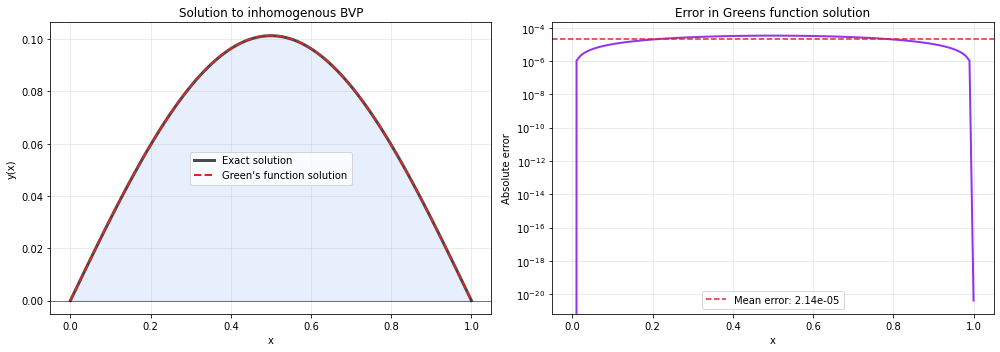

Maximum error: 3.401270e-05
Mean error: 2.143753e-05


In [13]:
f = np.sin(np.pi * grid)

y_exact = np.sin(np.pi * grid) / (np.pi**2)

dx = grid[1] - grid[0]
w_grid = sl_green.get_coefficients()['w']
y_greens = np.trapz(G * f[np.newaxis, :] * w_grid[np.newaxis, :], dx=dx, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(grid, y_exact, 'k-', linewidth=3, label='Exact solution', alpha=0.7)
ax.plot(grid, y_greens, '--', color='#dc2626', linewidth=2, label="Green's function solution")
ax.fill_between(grid, 0, y_exact, color='#2563eb', alpha=0.1)
ax.set_xlabel('x')
ax.set_ylabel('y(x)')
ax.set_title('Solution to inhomogenous BVP')
ax.legend()
ax.axhline(y=0, color='black', linewidth=0.5)

ax = axes[1]
error = np.abs(y_greens - y_exact)
ax.semilogy(grid, error, color='#9333ea', linewidth=2)
ax.set_xlabel('x')
ax.set_ylabel('Absolute error')
ax.set_title('Error in Greens function solution')
ax.axhline(y=np.mean(error), color='#dc2626', linestyle='--', label=f'Mean error: {np.mean(error):.2e}')
ax.legend()

plt.tight_layout()
plt.show()

print(f"Maximum error: {np.max(error):.6e}")
print(f"Mean error: {np.mean(error):.6e}")

### Convergence of Green's Function

The eigenfunction expansion converges as we include more terms.
This time we'll use a parabolic load, $$f(x) = x(1-x)$$ as our inhomogenous function with the exact solution $$y=x(1-2x^2+x^3)/12$$.

/tmp/ipykernel_29780/895856969.py:17: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  norm_sq = np.trapz(w_grid * basis[i]**2, dx=dx)
/tmp/ipykernel_29780/171840965.py:24: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  y_conv = np.trapz(G_conv * f_parabola[np.newaxis, :] * w_conv[np.newaxis, :], dx=dx, axis=1)


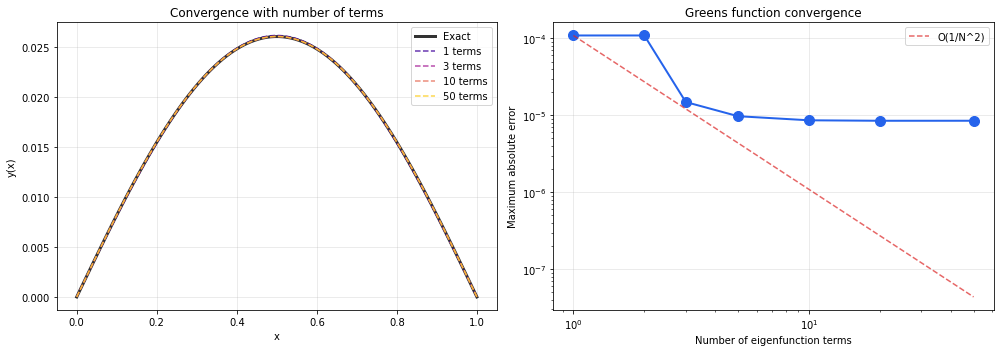

In [14]:
n_terms_list = [1, 2, 3, 5, 10, 20, 50]
errors_vs_terms = []

f_parabola = grid * (1 - grid)
# Correct exact solution: y = x(1 - 2x^2 + x^3)/12 for -y'' = x(1-x)
y_exact_parabola = grid * (1 - 2*grid**2 + grid**3) / 12

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(n_terms_list)))

ax = axes[0]
ax.plot(grid, y_exact_parabola, 'k-', linewidth=3, label='Exact', alpha=0.8)

for n_terms, color in zip(n_terms_list, colors):
    sl_conv = SturmLiouville()
    sl_conv.p(p_data).q(q_data).w(w_data)
    sl_conv.set_boundary_conditions('dirichlet')
    sl_conv.set_basis('fourier')
    sl_conv.preprocess(n_points=100)
    
    G_conv, _, _, _ = construct_greens_function(sl_conv, n_terms=n_terms)
    w_conv = sl_conv.get_coefficients()['w']
    y_conv = np.trapz(G_conv * f_parabola[np.newaxis, :] * w_conv[np.newaxis, :], dx=dx, axis=1)
    
    max_err = np.max(np.abs(y_conv - y_exact_parabola))
    errors_vs_terms.append(max_err)
    
    if n_terms in [1, 3, 10, 50]:
        ax.plot(grid, y_conv, '--', color=color, linewidth=1.5, 
                label=f'{n_terms} terms', alpha=0.8)

ax.set_xlabel('x')
ax.set_ylabel('y(x)')
ax.set_title('Convergence with number of terms')
ax.legend()

ax = axes[1]
ax.loglog(n_terms_list, errors_vs_terms, 'o-', color='#2563eb', linewidth=2, markersize=10)
ax.set_xlabel('Number of eigenfunction terms')
ax.set_ylabel('Maximum absolute error')
ax.set_title('Greens function convergence')

n_ref = np.array(n_terms_list)
err_ref = errors_vs_terms[0] * (1/n_ref)**2 / (1/n_terms_list[0])**2
ax.loglog(n_terms_list, err_ref, '--', color='#dc2626', alpha=0.7, label='O(1/N^2)')
ax.legend()

plt.tight_layout()
plt.show()

### Application: Steady-State Heat Conduction

Consider a rod with variable thermal conductivity $k(x)$ and internal heat generation $Q(x)$. The steady-state temperature distribution satisfies:

$$-\frac{d}{dx}\left[k(x)\frac{dT}{dx}\right] = Q(x)$$

with boundary conditions $T(0) = T(1) = 0$ (fixed temperature at ends).

/tmp/ipykernel_29780/895856969.py:17: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  norm_sq = np.trapz(w_grid * basis[i]**2, dx=dx)
/tmp/ipykernel_29780/975273384.py:21: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  T_solution = np.trapz(G_heat * Q_localized[np.newaxis, :], dx=dx_heat, axis=1)


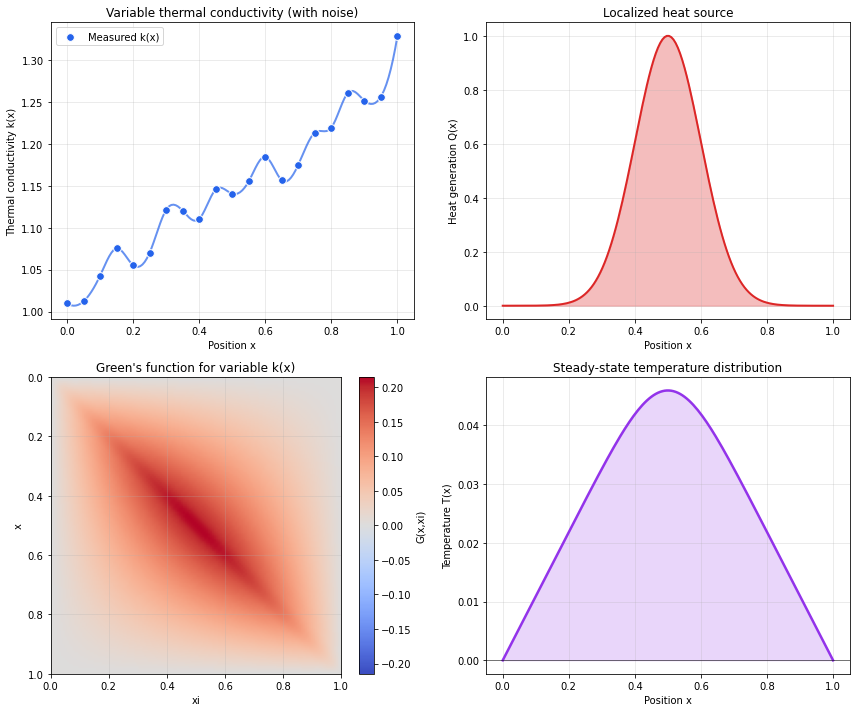

Maximum temperature: 0.0459 at x = 0.497


In [15]:
# Variable thermal conductivity with noise (simulating measurement error)
np.random.seed(42)
x_heat = np.linspace(0, 1, 21)
k_data = {x: 1.0 + 0.3*x + 0.02*np.random.randn() for x in x_heat}
k_data = {x: max(0.1, v) for x, v in k_data.items()}  # Ensure positivity
q_zero = {x: 0.0 for x in x_heat}
w_one = {x: 1.0 for x in x_heat}

sl_heat = SturmLiouville()
sl_heat.p(k_data).q(q_zero).w(w_one)
sl_heat.set_boundary_conditions('dirichlet')
sl_heat.set_basis('fourier')
sl_heat.preprocess(n_points=150)

G_heat, grid_heat, _, _ = construct_greens_function(sl_heat, n_terms=25)

# Localized Gaussian heat source
Q_localized = np.exp(-50*(grid_heat - 0.5)**2)

dx_heat = grid_heat[1] - grid_heat[0]
T_solution = np.trapz(G_heat * Q_localized[np.newaxis, :], dx=dx_heat, axis=1)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

ax = axes[0, 0]
k_interp = sl_heat.get_coefficients()['p']
ax.scatter(list(k_data.keys()), list(k_data.values()), s=60, c='#2563eb', 
           zorder=5, label='Measured k(x)', edgecolors='white')
ax.plot(grid_heat, k_interp, color='#2563eb', linewidth=2, alpha=0.7)
ax.set_xlabel('Position x')
ax.set_ylabel('Thermal conductivity k(x)')
ax.set_title('Variable thermal conductivity (with noise)')
ax.legend()

ax = axes[0, 1]
ax.plot(grid_heat, Q_localized, color='#dc2626', linewidth=2)
ax.fill_between(grid_heat, 0, Q_localized, color='#dc2626', alpha=0.3)
ax.set_xlabel('Position x')
ax.set_ylabel('Heat generation Q(x)')
ax.set_title('Localized heat source')

ax = axes[1, 0]
im = ax.imshow(G_heat, extent=[0, 1, 1, 0], aspect='auto', cmap='coolwarm',
               vmin=-np.max(np.abs(G_heat)), vmax=np.max(np.abs(G_heat)))
ax.set_xlabel('xi')
ax.set_ylabel('x')
ax.set_title("Green's function for variable k(x)")
plt.colorbar(im, ax=ax, label='G(x,xi)')

ax = axes[1, 1]
ax.plot(grid_heat, T_solution, color='#9333ea', linewidth=2.5)
ax.fill_between(grid_heat, 0, T_solution, color='#9333ea', alpha=0.2)
ax.set_xlabel('Position x')
ax.set_ylabel('Temperature T(x)')
ax.set_title('Steady-state temperature distribution')
ax.axhline(y=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

print(f"Maximum temperature: {np.max(T_solution):.4f} at x = {grid_heat[np.argmax(T_solution)]:.3f}")

### Application: 1-D Schrodinger Equation

The time-independent Schrodinger equation is a Sturm-Liouville problem:
$$-\frac{\hbar^2}{2m}\frac{d^2\psi}{dx^2} + V(x)\psi = E\psi$$
with $p(x) = 1/2$, $q(x) = V(x)$, $w(x) = 1$, and eigenvalue $\lambda = E$.

Here we solve the particle-in-a-box problem with a Gaussian potential

/tmp/ipykernel_29780/3389675742.py:32: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  norm = np.sqrt(np.trapz(psi**2, grid_qm))


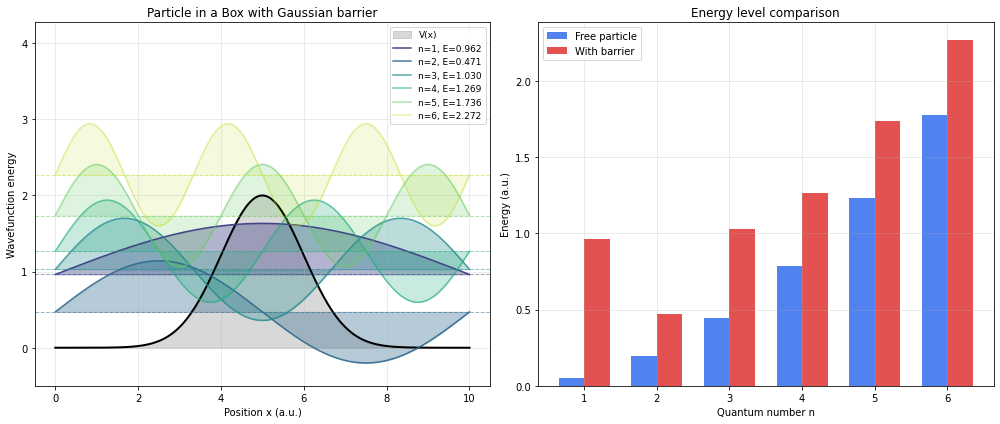

In [16]:
L = 10.0
x_qm = np.linspace(0, L, 51)

p_qm = {x: 0.5 for x in x_qm}
w_qm = {x: 1.0 for x in x_qm}

V0 = 2.0
sigma = 1.0
V_potential = {x: V0 * np.exp(-((x - L/2)**2) / (2*sigma**2)) for x in x_qm}

sl_qm = SturmLiouville()
sl_qm.p(p_qm).q(V_potential).w(w_qm)
sl_qm.set_boundary_conditions('dirichlet')
sl_qm.set_basis('fourier')
sl_qm.preprocess(n_points=200)

n_states = 6
basis_qm = sl_qm.generate_basis(n_basis=n_states)
grid_qm = sl_qm.get_grid()

energies = []
for i in range(n_states):
    coeffs_i = [1.0 if j == i else 0.0 for j in range(n_states)]
    E = sl_qm.rayleigh_quotient_from_coefficients(coeffs_i)
    energies.append(E)

V_grid = sl_qm.get_coefficients()['q']

wavefunctions = []
for i in range(n_states):
    psi = basis_qm[i]
    norm = np.sqrt(np.trapz(psi**2, grid_qm))
    wavefunctions.append(psi / norm)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
ax.fill_between(grid_qm, 0, V_grid, color='gray', alpha=0.3, label='V(x)')
ax.plot(grid_qm, V_grid, 'k-', linewidth=2)

colors = plt.cm.viridis(np.linspace(0.2, 0.9, n_states))
scale = 1.5

for i in range(n_states):
    E = energies[i]
    psi = wavefunctions[i]
    # Higher energy states get more transparent (lower alpha)
    line_alpha = 1.0 - 0.12 * i
    fill_alpha = 0.4 - 0.05 * i
    ax.axhline(y=E, color=colors[i], linestyle='--', alpha=0.5, linewidth=1)
    ax.plot(grid_qm, E + scale*psi, color=colors[i], linewidth=1.5, 
            label=f'n={i+1}, E={E:.3f}', alpha=line_alpha)
    ax.fill_between(grid_qm, E, E + scale*psi, color=colors[i], alpha=fill_alpha)

ax.set_xlabel('Position x (a.u.)')
ax.set_ylabel('Wavefunction energy')
ax.set_title('Particle in a Box with Gaussian barrier')
ax.legend(loc='upper right', fontsize=9)
ax.set_ylim(-0.5, max(energies) + 2)

ax = axes[1]
E_free = [(n**2 * np.pi**2) / (2 * L**2) for n in range(1, n_states + 1)]

x_pos = np.arange(n_states)
width = 0.35
ax.bar(x_pos - width/2, E_free, width, label='Free particle', color='#2563eb', alpha=0.8)
ax.bar(x_pos + width/2, energies, width, label='With barrier', color='#dc2626', alpha=0.8)

ax.set_xlabel('Quantum number n')
ax.set_ylabel('Energy (a.u.)')
ax.set_title('Energy level comparison')
ax.set_xticks(x_pos)
ax.set_xticklabels([str(i+1) for i in range(n_states)])
ax.legend()

plt.tight_layout()
plt.show()

### Green's Function for the Schrodinger Equation

The (retarded) Green's fucntion for the 1-D Schrodinger equation is:

$$G(x, x'; E) = \sum_n \frac{\psi_n(x) \psi_n^*(x')}{E - E_n + i\eta}$$

where $\eta \to 0^+$ is a small positive number to move the poles from the real line.

This Green's function describes both the local density of states (LDOS) $\rho(x, E) = -\frac{1}{\pi}\text{Im}[G(x, x; E)]$ as well as propagation amplitudes.

/tmp/ipykernel_29780/3886966961.py:36: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  total_dos = np.trapz(ldos, grid_qm, axis=1)


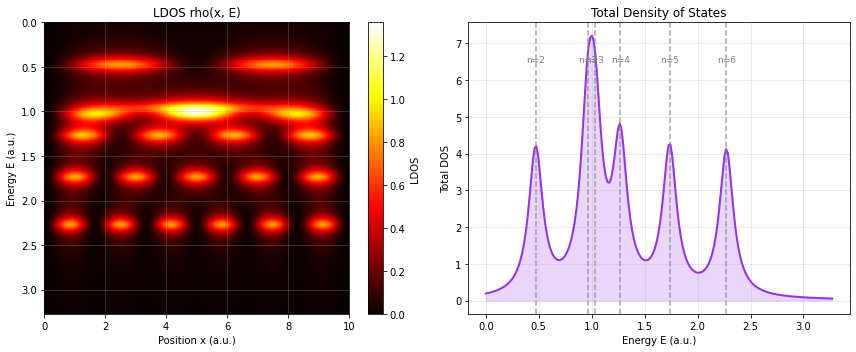

In [17]:
def quantum_greens_function(grid, wavefunctions, energies, E, eta=0.01):
    n_pts = len(grid)
    G = np.zeros((n_pts, n_pts), dtype=complex)
    
    for psi, E_n in zip(wavefunctions, energies):
        G += np.outer(psi, psi) / (E - E_n + 1j*eta)
    
    return G

def local_density_of_states(grid, wavefunctions, energies, E_range, eta=0.05):
    ldos = np.zeros((len(E_range), len(grid)))
    
    for i, E in enumerate(E_range):
        G = quantum_greens_function(grid, wavefunctions, energies, E, eta)
        ldos[i, :] = -np.diag(G).imag / np.pi
    
    return ldos

E_range = np.linspace(0, max(energies) + 1, 200)
eta = 0.08

ldos = local_density_of_states(grid_qm, wavefunctions, energies, E_range, eta)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
im = ax.imshow(ldos, extent=[0, L, E_range[-1], E_range[0]], 
               aspect='auto', cmap='hot', origin='upper')
ax.set_xlabel('Position x (a.u.)')
ax.set_ylabel('Energy E (a.u.)')
ax.set_title('LDOS rho(x, E)')
plt.colorbar(im, ax=ax, label='LDOS')

# Total DOS integrated over space
ax = axes[1]
total_dos = np.trapz(ldos, grid_qm, axis=1)
ax.plot(E_range, total_dos, color='#9333ea', linewidth=2)
ax.fill_between(E_range, 0, total_dos, color='#9333ea', alpha=0.2)

for i, E_n in enumerate(energies):
    ax.axvline(x=E_n, color='gray', linestyle='--', alpha=0.7)
    ax.annotate(f'n={i+1}', xy=(E_n, total_dos.max()*0.9), 
                fontsize=9, ha='center', color='gray')

ax.set_xlabel('Energy E (a.u.)')
ax.set_ylabel('Total DOS')
ax.set_title('Total Density of States')

plt.tight_layout()
plt.show()

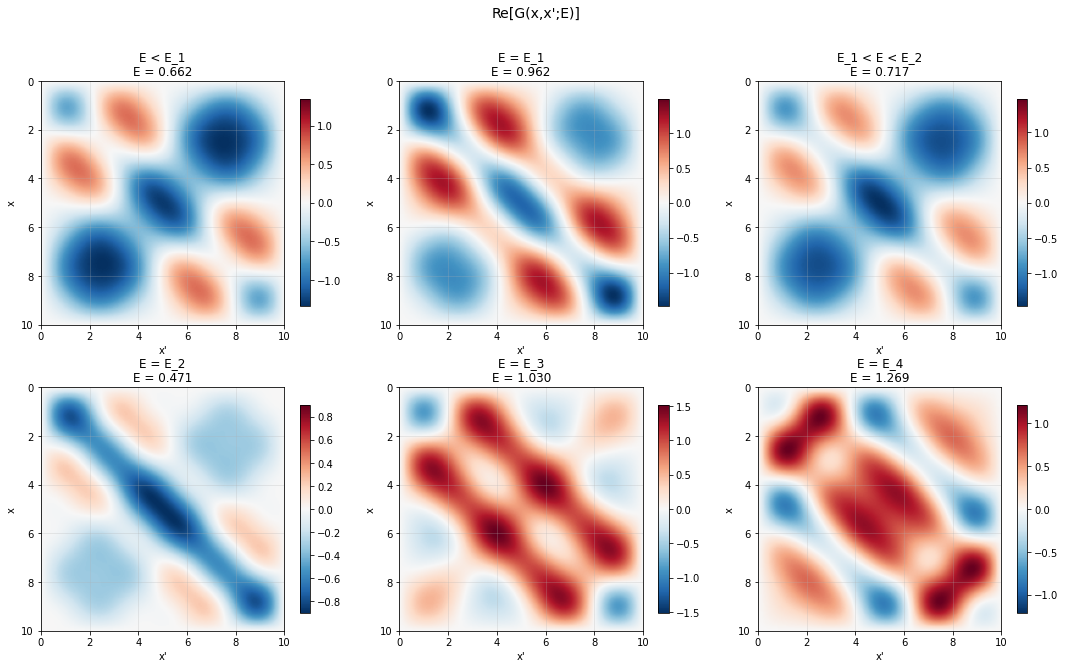

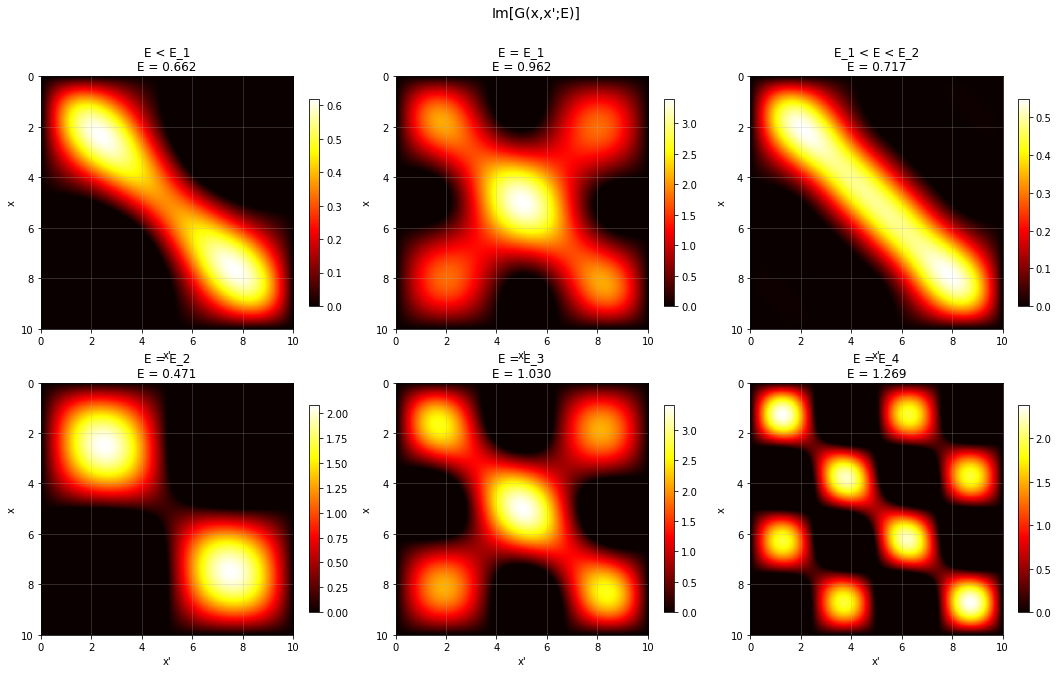

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

E_values = [energies[0] - 0.3, energies[0], (energies[0] + energies[1])/2, 
            energies[1], energies[2], energies[3]]
titles = ['E < E_1', 'E = E_1', 'E_1 < E < E_2', 
          'E = E_2', 'E = E_3', 'E = E_4']

for ax, E, title in zip(axes.flat, E_values, titles):
    G = quantum_greens_function(grid_qm, wavefunctions, energies, E, eta=0.1)
    
    im = ax.imshow(G.real, extent=[0, L, L, 0], aspect='equal', 
                   cmap='RdBu_r', vmin=-np.max(np.abs(G.real)), 
                   vmax=np.max(np.abs(G.real)))
    ax.set_xlabel("x'")
    ax.set_ylabel("x")
    ax.set_title(f'{title}\nE = {E:.3f}')
    plt.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle("Re[G(x,x';E)]", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, E, title in zip(axes.flat, E_values, titles):
    G = quantum_greens_function(grid_qm, wavefunctions, energies, E, eta=0.1)
    
    im = ax.imshow(-G.imag, extent=[0, L, L, 0], aspect='equal', 
                   cmap='hot', vmin=0, vmax=np.max(-G.imag))
    ax.set_xlabel("x'")
    ax.set_ylabel("x")
    ax.set_title(f'{title}\nE = {E:.3f}')
    plt.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle("Im[G(x,x';E)]", 
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()